In [2]:
!pip install -q monai segment-anything

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 6.9 MB/s eta 0:00:00a 0:00:01


In [1]:


import os
p = "/kaggle/input/datasets/hemantdarur/yolomodel-inference/yolo_checkpoints/tooth_yolo/weights"
print(os.listdir(p))

['last.pt', 'best.pt']


In [4]:
 !pip install -q monai segment-anything ultralytics

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


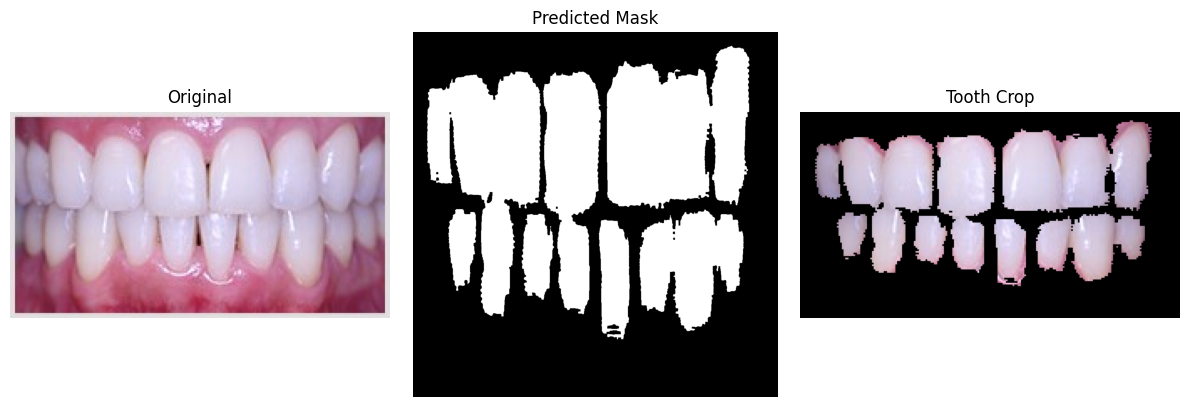

Saved tooth crop for patient9-2.jpg -> /kaggle/working/outputs/patient9-2_tooth_crop.png


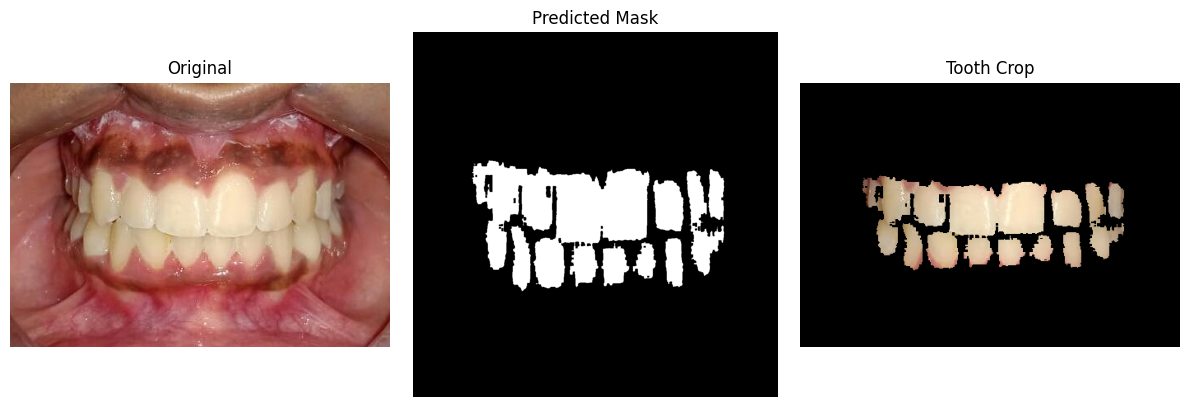

Saved tooth crop for 7836.jpg -> /kaggle/working/outputs/7836_tooth_crop.png


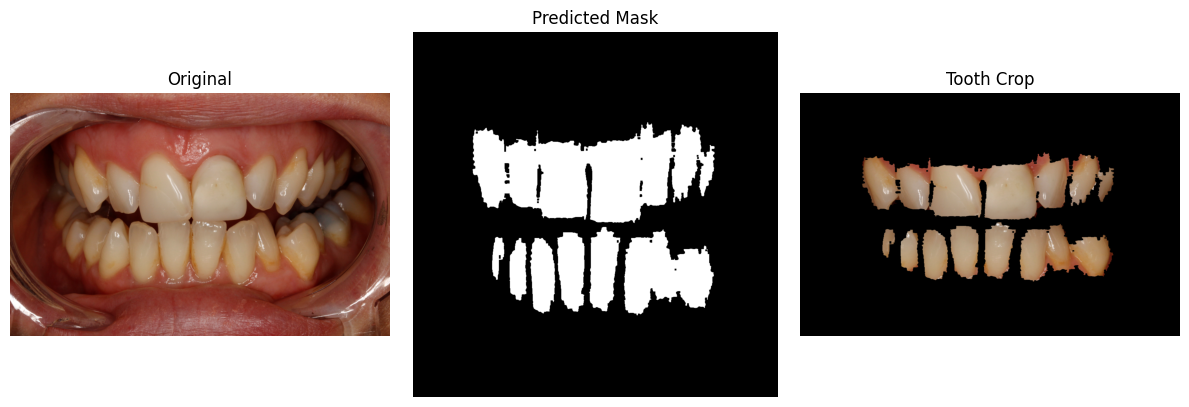

Saved tooth crop for 7018.jpg -> /kaggle/working/outputs/7018_tooth_crop.png


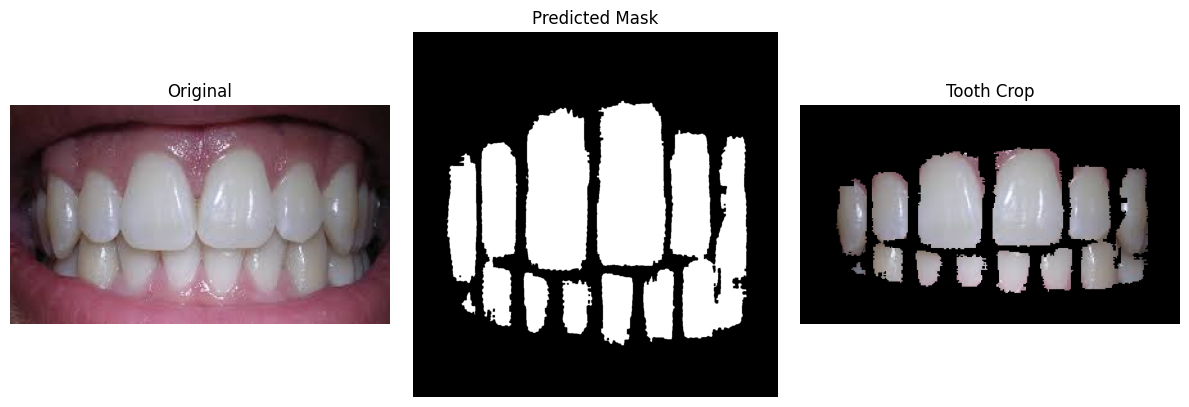

Saved tooth crop for yahya1.jpg -> /kaggle/working/outputs/yahya1_tooth_crop.png


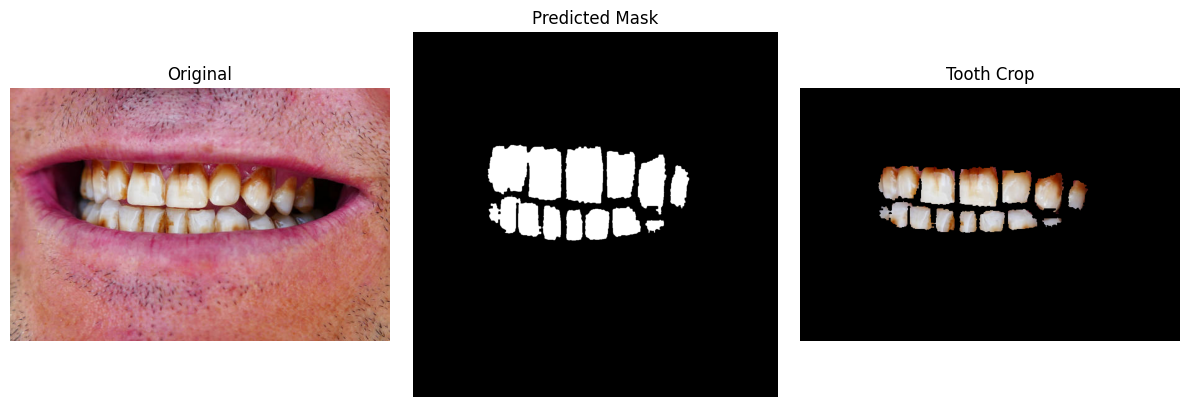

Saved tooth crop for istockphoto-1002774754-612x612.jpg -> /kaggle/working/outputs/istockphoto-1002774754-612x612_tooth_crop.png


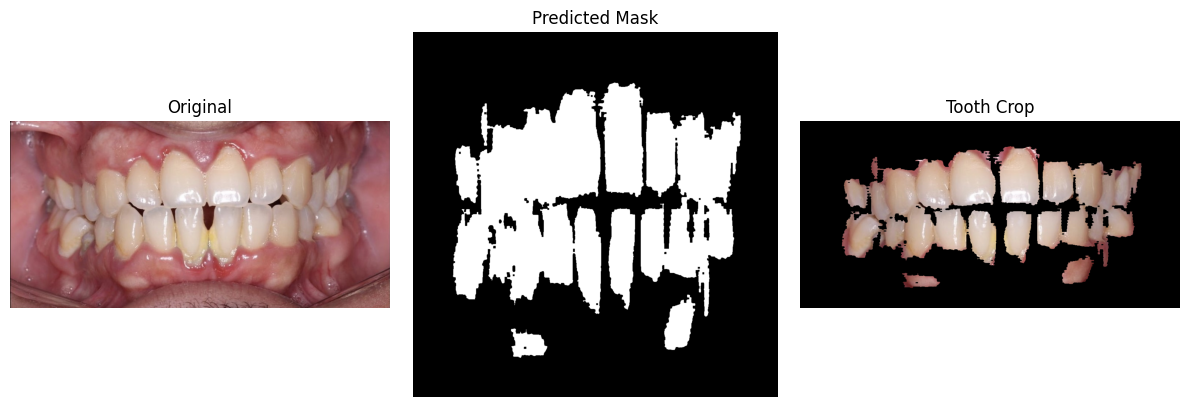

Saved tooth crop for IMG_2423.jpg -> /kaggle/working/outputs/IMG_2423_tooth_crop.png


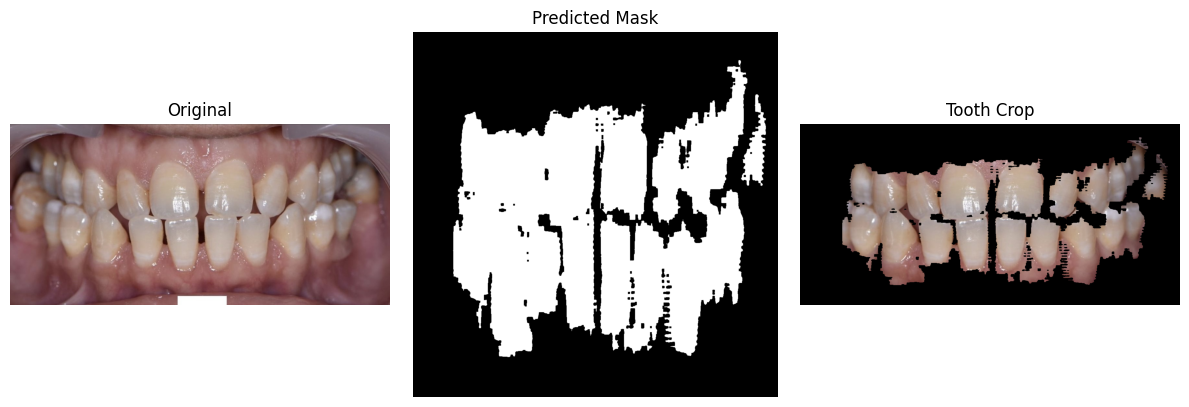

Saved tooth crop for IMG_2385.jpg -> /kaggle/working/outputs/IMG_2385_tooth_crop.png


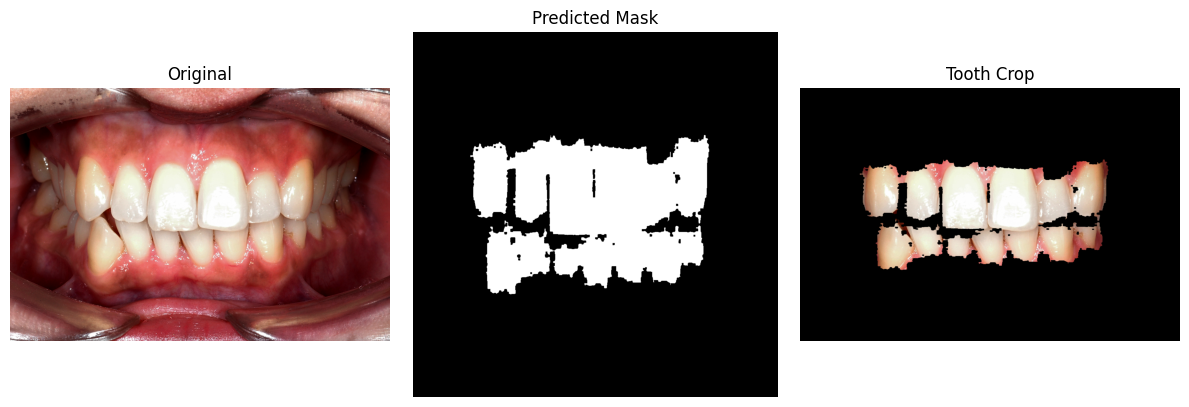

Saved tooth crop for 8764.jpg -> /kaggle/working/outputs/8764_tooth_crop.png


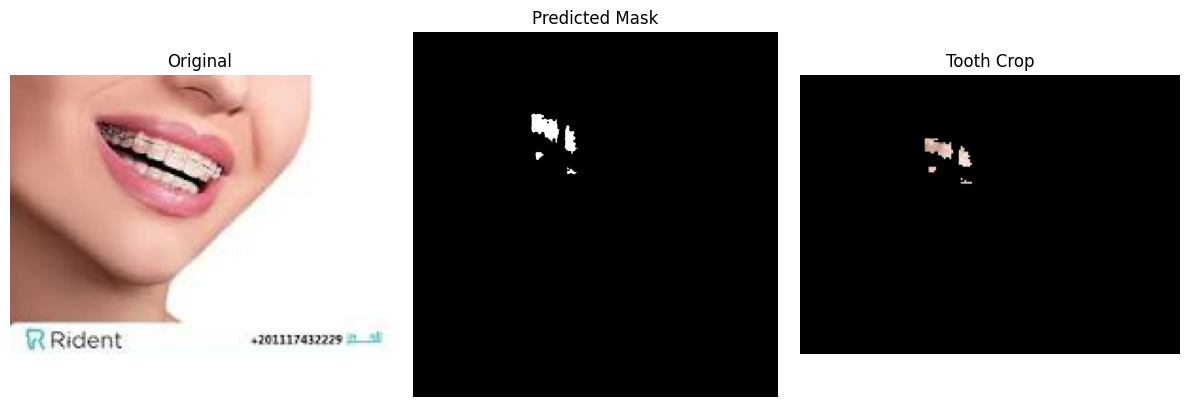

Saved tooth crop for y9.jpeg -> /kaggle/working/outputs/y9_tooth_crop.png


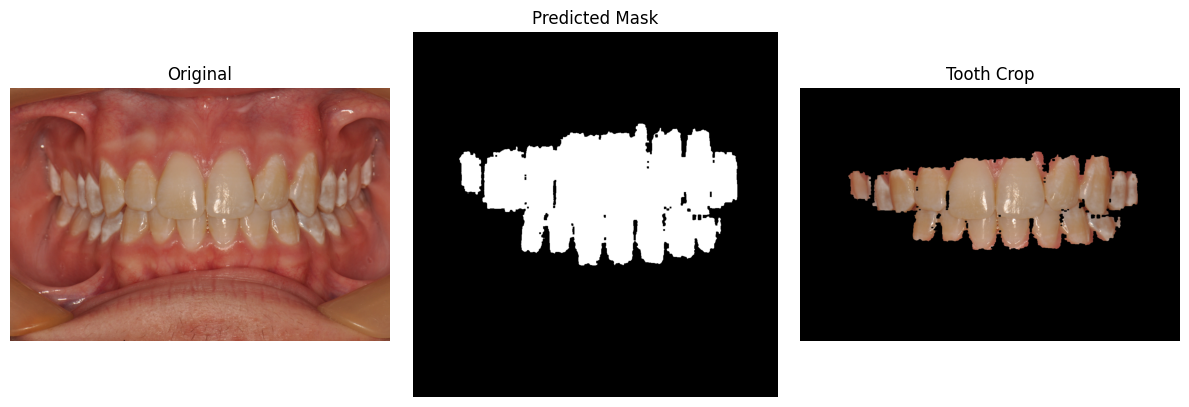

Saved tooth crop for 7758.jpg -> /kaggle/working/outputs/7758_tooth_crop.png


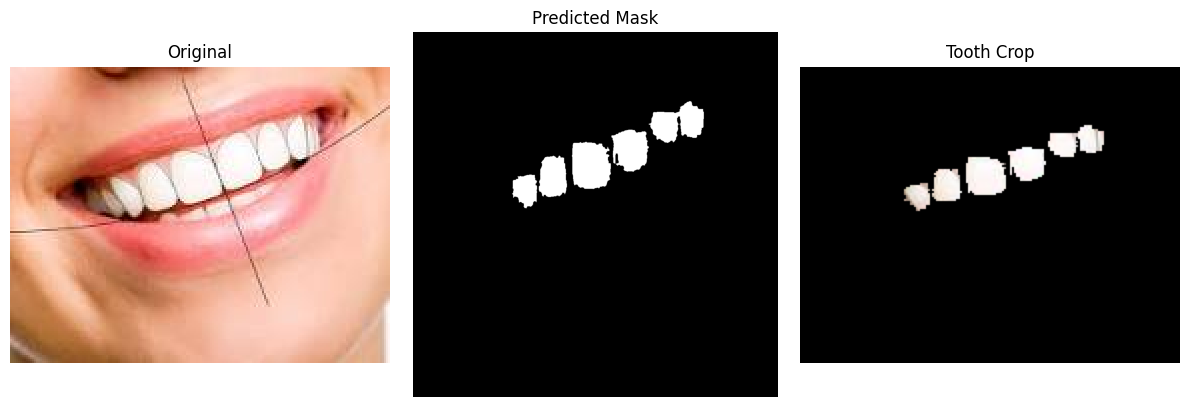

Saved tooth crop for y17.jpeg -> /kaggle/working/outputs/y17_tooth_crop.png


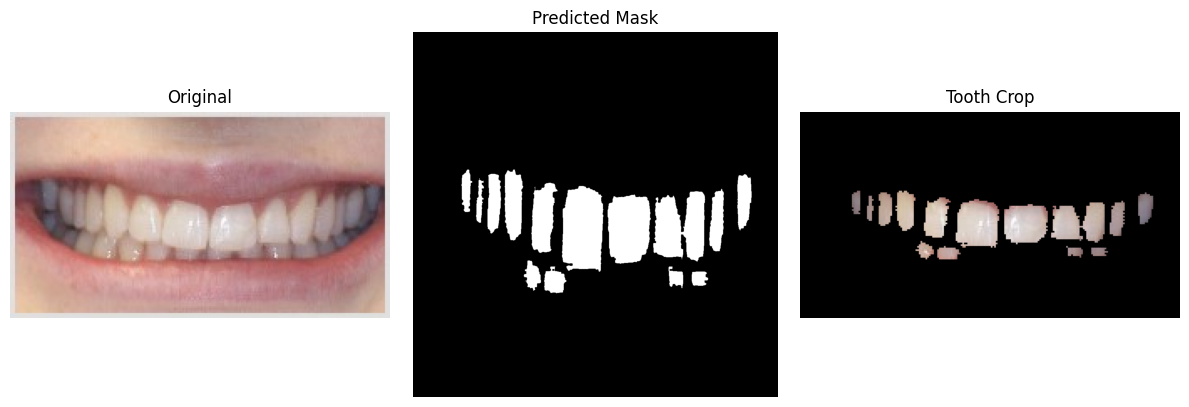

Saved tooth crop for patient17-2.jpg -> /kaggle/working/outputs/patient17-2_tooth_crop.png


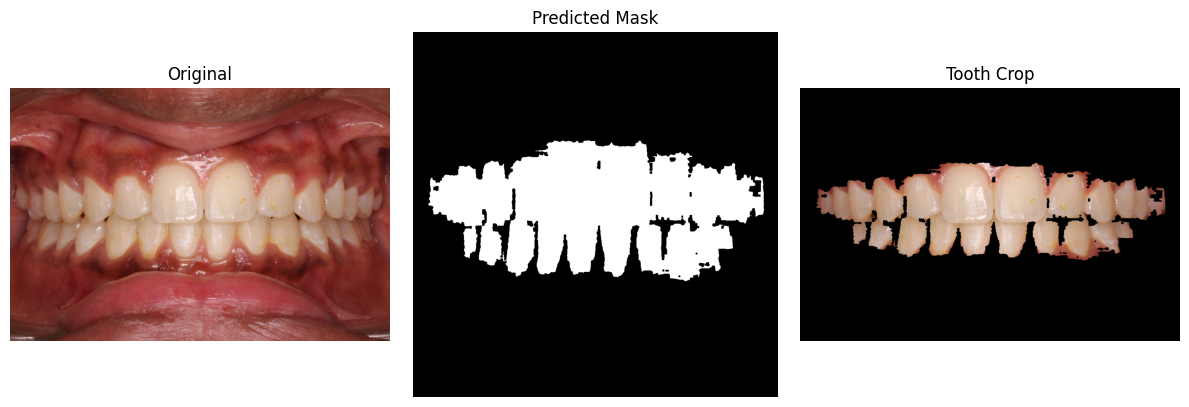

Saved tooth crop for 7625.jpg -> /kaggle/working/outputs/7625_tooth_crop.png


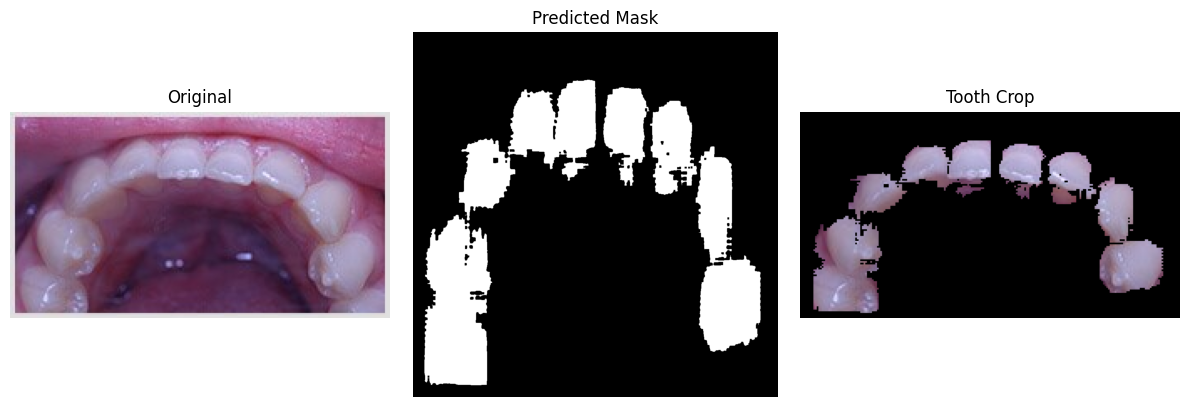

Saved tooth crop for patient4-2.jpg -> /kaggle/working/outputs/patient4-2_tooth_crop.png


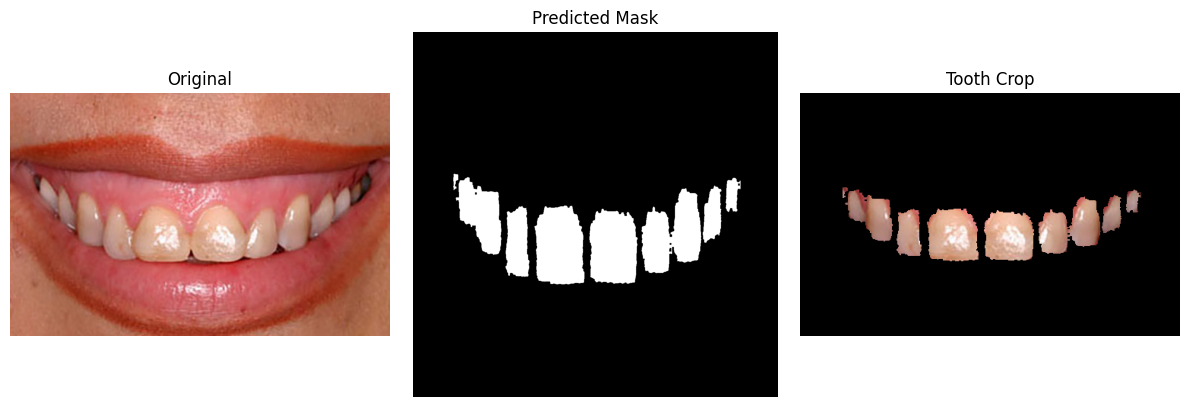

Saved tooth crop for mous15.jpg -> /kaggle/working/outputs/mous15_tooth_crop.png


In [5]:
import os
import random
import numpy as np
import torch
import torch.nn.functional as F
import cv2
import matplotlib.pyplot as plt
from skimage.transform import resize
from segment_anything import sam_model_registry
from ultralytics import YOLO

# --------------------------------------------------------------------------
# CONSTANTS
# --------------------------------------------------------------------------
# infer.py runs in Notebook B, a separate Kaggle session from Notebook A, so
# it can't read Notebook A's /kaggle/working directly. Notebook A's trained
# checkpoint was published as its own Kaggle Dataset ("notebook-a-meowmeow")
# and attached to Notebook B, confirmed path below.
CHECKPOINT_PATH = "/kaggle/input/datasets/hemantdarur/notebook-a-meowmeow/checkpoints/medsam_tooth_best.pth"

# Published from module_2b_yolo_localization/train_yolo.py's Kaggle output
# (same Notebook A -> Dataset -> Notebook B handoff as CHECKPOINT_PATH above).
# Kaggle preserves the /kaggle/working subfolder structure, so this mirrors
# train_yolo.py's OUTPUT_DIR/tooth_yolo/weights/best.pt.
YOLO_CHECKPOINT_PATH = "/kaggle/input/datasets/hemantdarur/yolomodel-inference/yolo_checkpoints/tooth_yolo/weights/best.pt"

OUTPUT_DIR = "/kaggle/working/outputs"
VAL_IMAGES_DIR = "/kaggle/input/datasets/alielhenidy/tooth-dataset/Tooth dataset v4/val/images"

IMG_SIZE = 1024
MASK_THRESHOLD = 0.9  # see docs/DISCUSSION_segmentation_next_steps.md - 0.9 gave
                       # noticeably less gum/lip leakage than 0.5 on the same 15-image sample
NUM_SAMPLE_IMAGES = 15  # matches the earlier 0.5-vs-0.9 threshold comparison sample size
                         # (same RANDOM_SEED below) so this run is directly comparable
RANDOM_SEED = 42

# Toggle for a clean before/after comparison against the existing generic-box
# results: True uses the trained YOLO detector's box, False reverts to the
# old fixed-margin box with nothing else changed. Falls back to the generic
# box automatically per-image if YOLO finds nothing (see get_bbox_prompt_yolo).
USE_YOLO_PROMPT = True

YOLO_CONF_THRESHOLD = 0.25  # ultralytics' own default
# Expand-only margin (pixels, in the 1024x1024 working resolution) added
# around YOLO's box. MedSAM was trained on GT-derived boxes randomly jittered
# by up to module_2's BBOX_SHIFT (20px) - this keeps the inference-time box a
# similar scale to what the model actually learned to be robust to, rather
# than handing it a pixel-tight box it never saw in training.
YOLO_BBOX_MARGIN = 20

# Post-processing on the raw thresholded mask (see docs/EXPERIMENTS.md,
# "module_2b YOLO localization" section) - fixes fragmented/noisy masks
# without touching the model itself. Deliberately does NOT keep only the
# largest connected component: a healthy anterior tooth row is naturally
# several disconnected components (gaps between teeth), so that would cut
# real teeth out. Instead drops only components far smaller than the
# largest one (noise blobs), and closes small internal gaps.
ENABLE_MASK_CLEANUP = True
CLEANUP_CLOSE_KERNEL_SIZE = 5
CLEANUP_MIN_COMPONENT_FRACTION = 0.01  # relative to the largest component's area

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# --------------------------------------------------------------------------
# MODEL LOADING
# --------------------------------------------------------------------------
def load_model(checkpoint_path):
    # vit_b architecture must match what was fine-tuned in module_2; we load
    # it with no checkpoint first, then load our fine-tuned weights on top.
    model = sam_model_registry["vit_b"](checkpoint=None)
    state_dict = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(state_dict)
    model.to(DEVICE)
    model.eval()
    return model


def load_yolo_model(checkpoint_path):
    # Returns None (rather than raising) if the checkpoint isn't there yet -
    # lets the rest of the script fall back to the generic box for the whole
    # run instead of crashing, since publishing the YOLO checkpoint is a
    # separate Kaggle step (see module_2b's notes.md) that may not have
    # happened yet.
    if not os.path.exists(checkpoint_path):
        print(f"YOLO checkpoint not found at {checkpoint_path} - "
              f"falling back to the generic box prompt for this run.")
        return None
    return YOLO(checkpoint_path)


# --------------------------------------------------------------------------
# PREPROCESSING
# --------------------------------------------------------------------------
def preprocess_image(image_path):
    image_bgr = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    image_resized = resize(
        image_rgb, (IMG_SIZE, IMG_SIZE), order=3, preserve_range=True, anti_aliasing=True
    )
    image_normalized = (image_resized / 255.0).astype(np.float32)

    image_tensor = torch.from_numpy(image_normalized).permute(2, 0, 1).unsqueeze(0).float()
    # uint8 copy of the same resized frame, returned separately for YOLO -
    # SAM needs the normalized float tensor, YOLO expects a plain uint8 image.
    image_resized_uint8 = image_resized.astype(np.uint8)
    return image_tensor, image_rgb, image_resized_uint8


# --------------------------------------------------------------------------
# BBOX PROMPT (no ground truth available at inference time)
# --------------------------------------------------------------------------
def get_bbox_prompt(image_shape, margin_fraction=0.1):
    # With no GT mask to derive a bbox from, we fall back to a generous
    # centered box covering most of the image, since input photos are assumed
    # to already be roughly cropped around the mouth/teeth region.
    h, w = image_shape[:2]
    margin_x = int(w * margin_fraction)
    margin_y = int(h * margin_fraction)
    return np.array([margin_x, margin_y, w - margin_x, h - margin_y], dtype=np.float32)


def get_bbox_prompt_yolo(image_resized_uint8, yolo_model, margin=YOLO_BBOX_MARGIN):
    # image_resized_uint8 is already in the 1024x1024 working resolution, so
    # the box YOLO returns is directly usable as a SAM prompt with no extra
    # coordinate conversion.
    results = yolo_model.predict(image_resized_uint8, conf=YOLO_CONF_THRESHOLD, verbose=False)
    boxes = results[0].boxes.xyxy.cpu().numpy()

    if boxes.shape[0] == 0:
        return None  # caller falls back to the generic box for this image

    # MedSAM was trained on ONE box spanning the entire GT tooth mask (see
    # module_2's get_bbox_from_mask), not one box per tooth - so if YOLO
    # fires multiple boxes (e.g. separate upper/lower arches), take the union
    # of all of them rather than only the highest-confidence single box, to
    # match that training distribution.
    x_min = boxes[:, 0].min()
    y_min = boxes[:, 1].min()
    x_max = boxes[:, 2].max()
    y_max = boxes[:, 3].max()

    h, w = image_resized_uint8.shape[:2]
    x_min = max(0, x_min - margin)
    y_min = max(0, y_min - margin)
    x_max = min(w, x_max + margin)
    y_max = min(h, y_max + margin)

    return np.array([x_min, y_min, x_max, y_max], dtype=np.float32)


# --------------------------------------------------------------------------
# MASK CLEANUP
# --------------------------------------------------------------------------
def cleanup_mask(mask, min_component_fraction=CLEANUP_MIN_COMPONENT_FRACTION,
                  close_kernel_size=CLEANUP_CLOSE_KERNEL_SIZE):
    kernel = np.ones((close_kernel_size, close_kernel_size), np.uint8)
    closed = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(closed, connectivity=8)
    if num_labels <= 1:  # only the background label - nothing to clean
        return closed

    largest_area = stats[1:, cv2.CC_STAT_AREA].max()
    min_area = largest_area * min_component_fraction

    cleaned = np.zeros_like(closed)
    for label_id in range(1, num_labels):
        if stats[label_id, cv2.CC_STAT_AREA] >= min_area:
            cleaned[labels == label_id] = 1
    return cleaned


# --------------------------------------------------------------------------
# INFERENCE
# --------------------------------------------------------------------------
def run_inference(model, image_tensor, bbox):
    image_tensor = image_tensor.to(DEVICE)
    box_torch = torch.as_tensor(bbox, dtype=torch.float32, device=DEVICE).view(1, 1, 4)

    with torch.no_grad():
        image_embedding = model.image_encoder(image_tensor)
        sparse_embeddings, dense_embeddings = model.prompt_encoder(
            points=None, boxes=box_torch, masks=None,
        )
        low_res_masks, _ = model.mask_decoder(
            image_embeddings=image_embedding,
            image_pe=model.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse_embeddings,
            dense_prompt_embeddings=dense_embeddings,
            multimask_output=False,
        )
        upsampled = F.interpolate(
            low_res_masks, size=image_tensor.shape[-2:], mode="bilinear", align_corners=False
        )
        probs = torch.sigmoid(upsampled)

    mask = (probs.squeeze().cpu().numpy() > MASK_THRESHOLD).astype(np.uint8)
    if ENABLE_MASK_CLEANUP:
        mask = cleanup_mask(mask)
    return mask


# --------------------------------------------------------------------------
# TOOTH CROP EXTRACTION
# --------------------------------------------------------------------------
def extract_tooth_crop(original_image, mask, save_path):
    # Resize the (1024x1024) mask back down to the original image's resolution
    # so it can be applied pixel-for-pixel.
    mask_resized = cv2.resize(
        mask, (original_image.shape[1], original_image.shape[0]), interpolation=cv2.INTER_NEAREST
    )
    mask_3ch = np.repeat(mask_resized[:, :, None], 3, axis=2)
    tooth_crop = original_image * mask_3ch  # zeroes out everything outside the tooth region

    cv2.imwrite(save_path, cv2.cvtColor(tooth_crop, cv2.COLOR_RGB2BGR))
    return tooth_crop


# --------------------------------------------------------------------------
# VISUALIZATION
# --------------------------------------------------------------------------
def visualize_result(original_image, mask, tooth_crop, save_path):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(original_image)
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Predicted Mask")
    axes[1].axis("off")

    axes[2].imshow(tooth_crop)
    axes[2].set_title("Tooth Crop")
    axes[2].axis("off")

    plt.tight_layout()
    plt.savefig(save_path)
    plt.show()


# --------------------------------------------------------------------------
# MAIN
# --------------------------------------------------------------------------
if __name__ == "__main__":
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    random.seed(RANDOM_SEED)

    model = load_model(CHECKPOINT_PATH)
    yolo_model = load_yolo_model(YOLO_CHECKPOINT_PATH) if USE_YOLO_PROMPT else None

    all_images = sorted(
        f for f in os.listdir(VAL_IMAGES_DIR) if f.lower().endswith((".jpg", ".jpeg"))
    )
    sample_images = random.sample(all_images, min(NUM_SAMPLE_IMAGES, len(all_images)))

    for filename in sample_images:
        image_path = os.path.join(VAL_IMAGES_DIR, filename)
        base_name = os.path.splitext(filename)[0]

        image_tensor, original_image, image_resized_uint8 = preprocess_image(image_path)

        bbox = None
        if yolo_model is not None:
            bbox = get_bbox_prompt_yolo(image_resized_uint8, yolo_model)
            if bbox is None:
                print(f"  YOLO found no tooth region in {filename} - using generic box instead")
        if bbox is None:
            bbox = get_bbox_prompt(image_tensor.shape[-2:])

        mask = run_inference(model, image_tensor, bbox)

        crop_path = os.path.join(OUTPUT_DIR, f"{base_name}_tooth_crop.png")
        tooth_crop = extract_tooth_crop(original_image, mask, crop_path)

        viz_path = os.path.join(OUTPUT_DIR, f"{base_name}_medsam_result.png")
        visualize_result(original_image, mask, tooth_crop, viz_path)

        print(f"Saved tooth crop for {filename} -> {crop_path}")
